CREDIT RISK SCORECARD PROJECT

Dataset Created Successfully
     Income  Credit_History  Loan_Amount  Debt_Ratio  Employment_Years  \
0  0.351385        2.182377    -0.255875   -0.388255          0.892724   
1 -1.800301        0.169075     1.640729   -1.884878          2.475151   
2 -0.662567       -0.965904    -1.349986   -0.151772          0.034064   
3  0.071325        1.530983    -0.103807   -0.220439          0.841334   
4 -0.251711       -1.705038    -1.373556    0.320075         -0.823443   

   Credit_Utilization  Default_Risk  
0           -0.868436             1  
1            0.236966             0  
2           -1.147303             0  
3            1.106722             0  
4           -0.662904             0  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Income              1000 non-null   f

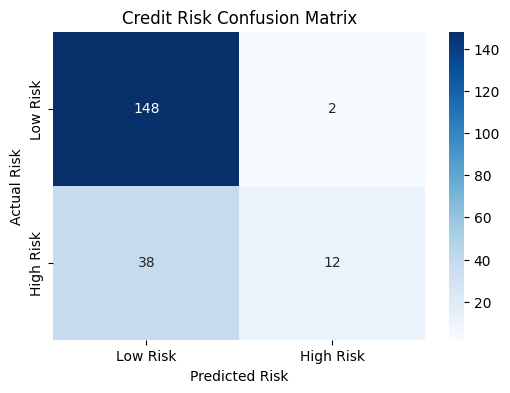

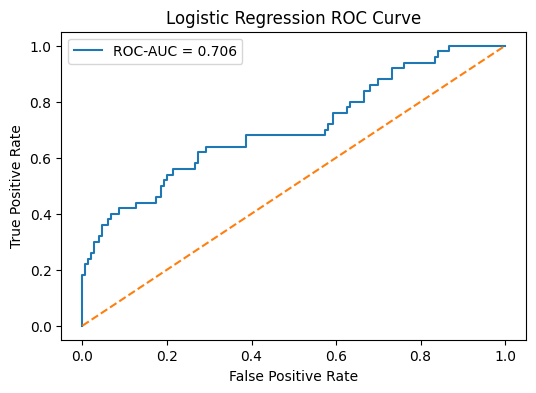


CREDIT RISK SCORECARD
              Feature  Coefficient            Risk_Influence
0              Income     0.521736  Increases Predicted Risk
1      Credit_History     0.304717  Increases Predicted Risk
2         Loan_Amount     0.010597  Increases Predicted Risk
3          Debt_Ratio     0.350962  Increases Predicted Risk
4    Employment_Years    -0.289028  Decreases Predicted Risk
5  Credit_Utilization    -0.152065  Decreases Predicted Risk


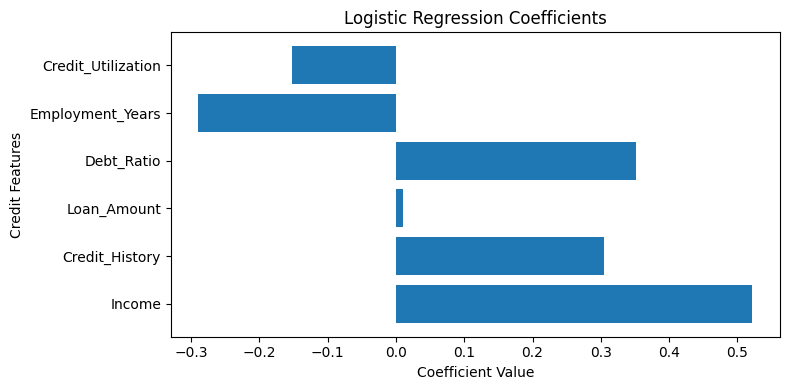


SAMPLE CREDIT RISK PREDICTIONS
       Income  Credit_History  Loan_Amount  Debt_Ratio  Employment_Years  \
673 -0.245085        1.997859     0.324689    0.121027          1.113296   
966  1.575738       -0.050676     1.801540    0.754894         -1.551180   
558  1.395268       -0.969713    -0.528629    2.549482         -2.843692   
383 -0.003077       -4.497019    -1.597796    0.037253         -1.766491   
670 -0.183427        0.321826    -0.541686   -1.819455          1.530125   
348 -0.969601       -1.002641     0.351746   -1.009607          0.779215   
356 -0.910442        0.970646    -0.352424   -1.078939          1.733076   
727 -2.017609        1.569931     1.686304   -1.060117          2.582776   
51  -0.041766       -2.947250    -0.019196   -0.318597         -1.270614   
81  -2.903239       -1.202586    -1.014923   -3.367777          3.429850   

     Credit_Utilization  Actual_Risk  Predicted_Risk  Default_Probability  \
673            1.948207            0               0  

In [2]:

# ============================================================
# CREDIT RISK SCORECARD AND LOGISTIC REGRESSION VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("CREDIT RISK SCORECARD PROJECT")
print("=" * 60)

# 1. GENERATE CREDIT RISK DATASET

X, y = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    weights=[0.75, 0.25],
    random_state=42
)

columns = [
    "Income",
    "Credit_History",
    "Loan_Amount",
    "Debt_Ratio",
    "Employment_Years",
    "Credit_Utilization"
]

df = pd.DataFrame(X, columns=columns)
df["Default_Risk"] = y

print("\nDataset Created Successfully")
print(df.head())

# 2. DATASET INFORMATION

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRisk Distribution:")
print(df["Default_Risk"].value_counts())

# 3. SEPARATE FEATURES AND TARGET

X = df.drop("Default_Risk", axis=1)
y = df["Default_Risk"]

# 4. TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. FEATURE SCALING

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# 6. LOGISTIC REGRESSION MODEL

model = LogisticRegression(
    max_iter=500,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("\nLogistic Regression Model Trained Successfully")

# 7. PREDICTIONS

y_pred = model.predict(X_test_scaled)
y_probability = model.predict_proba(X_test_scaled)[:, 1]

# 8. MODEL VALIDATION

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("\nMODEL PERFORMANCE")
print("=" * 40)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 9. CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.title("Credit Risk Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.show()

# 10. ROC CURVE

fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("Logistic Regression ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# 11. CREDIT RISK SCORECARD

scorecard = pd.DataFrame({
    "Feature": columns,
    "Coefficient": model.coef_[0]
})

scorecard["Risk_Influence"] = np.where(
    scorecard["Coefficient"] > 0,
    "Increases Predicted Risk",
    "Decreases Predicted Risk"
)

print("\nCREDIT RISK SCORECARD")
print(scorecard)

# 12. FEATURE IMPORTANCE VISUALIZATION

plt.figure(figsize=(8, 4))

plt.barh(
    scorecard["Feature"],
    scorecard["Coefficient"]
)

plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Credit Features")
plt.tight_layout()
plt.show()

# 13. SAMPLE CREDIT RISK PREDICTIONS

results = X_test.copy()

results["Actual_Risk"] = y_test.values
results["Predicted_Risk"] = y_pred
results["Default_Probability"] = y_probability

results["Risk_Category"] = np.where(
    results["Default_Probability"] >= 0.5,
    "High Risk",
    "Low Risk"
)

print("\nSAMPLE CREDIT RISK PREDICTIONS")
print(results.head(10))

# 14. SAVE RESULTS

results.to_csv("Credit_Risk_Predictions.csv", index=False)
scorecard.to_csv("Credit_Risk_Scorecard.csv", index=False)

# 15. FINAL SUMMARY

print("\n" + "=" * 60)
print("PROJECT EXECUTION COMPLETED SUCCESSFULLY")
print("=" * 60)

print("Dataset Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Model: Logistic Regression")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("ROC-AUC:", round(roc_auc, 4))

print("\nGenerated Files:")
print("1. Credit_Risk_Predictions.csv")
print("2. Credit_Risk_Scorecard.csv")

print("\nCREDIT RISK SCORECARD AND LOGISTIC REGRESSION")
print("VALIDATION COMPLETED!")
